# 08c — EDA phần C: CHẤT NÀO (người phụ trách: Chennai/Hyderabad)

**Câu hỏi nghiên cứu chung**

> **Ô nhiễm không khí nặng (AQI từ 201 trở lên) tập trung ở thành phố nào và vào mùa nào trong 8 thành phố Ấn Độ giai đoạn 2015–2020, để cơ quan môi trường và người dân biết nên ưu tiên cảnh báo sức khỏe và giảm phát thải ở đâu, lúc nào?**


**Quy ước chung** (chi tiết ở `08_eda.ipynb`): so sánh giữa thành phố chỉ dùng `win` (khoảng chung); "nặng" = AQI >= 201 trên số ngày **có AQI**;
mùa: Đông (12-2), Hè (3-5), Mưa (6-9), Sau mưa (10-11); chỉ viết "có liên quan", **không** viết "gây ra".
Hàm dùng chung nằm ở `src/eda_utils.py` (không sửa nếu chưa báo nhóm).

**Làm việc nhóm:** chỉ sửa notebook **này** và chỉ lưu hình có tên của phần mình (`eda_<số>_...png`). `git pull` trước khi push.

## Việc cần làm
1. **Biểu đồ 4**: PM2.5 với AQI (và/hoặc ma trận tương quan Spearman các chất trong `USABLE`; thang màu phân kỳ **neo tại 0**).
2. Khi AQI nặng (>= 201) chất nào ở mức cao nhất? (mô tả, kèm lưu ý bên dưới)
3. Sau khi A và B xong: **tổng hợp mục 5 và mục 6** ở cuối notebook này, và soạn bộ câu vấn đáp.

## Lưu ý quan trọng
AQI của CPCB được tính từ **mức cao nhất trong các chỉ số con của từng chất**, nên AQI và PM2.5 tương quan cao một phần **do cách tính**, không phải một phát hiện. Hãy nói rõ điều này trong báo cáo.
Khi thử dựng lại AQI từ các chất theo bảng CPCB, kết quả chỉ khớp (lệch tối đa 10 điểm) khoảng 33% số ngày, nên **không** khẳng định chắc chắn "chất nào đóng góp"; chỉ mô tả "chất nào ở mức cao nhất".

## Chuẩn biểu đồ (W7), tick đủ trước khi push

- [ ] Tiêu đề là **kết luận có con số** (không phải "AQI theo thành phố")
- [ ] Trục có **nhãn và đơn vị**
- [ ] Biểu đồ cột **bắt đầu từ 0**, sắp theo giá trị (không theo bảng chữ cái)
- [ ] **Một** màu nhấn cho điều muốn người đọc thấy, còn lại màu trung tính
- [ ] Ghi nhãn trực tiếp, bỏ legend nếu chỉ có một nhóm
- [ ] Không dùng biểu đồ tròn, 3D, trục kép; không dùng chỉ đỏ-xanh lá để phân biệt
- [ ] Thử chuyển sang thang xám vẫn đọc được
- [ ] Chú thích có cỡ mẫu và ngày dữ liệu (hàm `finish_chart` đã làm sẵn)

## 0. Setup

In [1]:
import sys, os
sys.path.append(os.path.abspath("../src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from eda_utils import (CITIES, USABLE, SEASON_ORDER, ACCENT, NEUTRAL,
                       vn, load, poor_share, four_families, finish_chart, save_fig, set_style)

set_style()
eda, win, START, END = load()      # eda: toàn bộ 2015-2020 | win: khoảng chung của 8 thành phố (dùng khi so sánh giữa thành phố)

Toàn bộ: 14.056 dòng, 01/01/2015 - 01/07/2020
Khoảng chung (biến win): 14/06/2017 - 01/07/2020, 8.912 dòng; 8.734 ngày có AQI


## C0. Tương quan Spearman giữa các chất đủ dữ liệu và AQI (khoảng chung)

In [2]:
corr = win[USABLE + ["AQI"]].corr(method="spearman").round(2)
corr

,PM2.5,NO2,CO,SO2,O3,AQI
PM2.5,1.00,0.50,0.44,0.34,0.25,0.91
NO2,0.50,1.00,0.43,0.27,0.26,0.52
CO,0.44,0.43,1.00,0.20,0.17,0.48
SO2,0.34,0.27,0.20,1.00,0.28,0.38
O3,0.25,0.26,0.17,0.28,1.00,0.34
AQI,0.91,0.52,0.48,0.38,0.34,1.00


### Đọc bảng C0 bằng lời

Bảng tính trên **khoảng chung** (14/06/2017 – 01/07/2020), gộp 8 thành phố. Dùng **Spearman** (tương quan hạng: hai chất cùng có ngày cao, ngày thấp thì hệ số cao; không đòi hỏi quan hệ đường thẳng nên hợp với dữ liệu lệch phải). Mỗi cặp chỉ dùng các ngày có đủ cả hai giá trị.

| Đọc | Từ bảng này |
|---|---|
| Cột `AQI` | PM2.5 **0,91**, còn NO2 0,52, CO 0,48, SO2 0,38, O3 0,34. PM2.5 đi cùng AQI chặt hơn hẳn bốn chất kia. |
| Giữa các chất với nhau | Từ 0,17 (CO với O3) đến 0,50 (PM2.5 với NO2): các chất tăng giảm khá độc lập, không chất nào "đại diện" cho các chất còn lại. |
| Vì sao PM2.5 cao như vậy | AQI của CPCB lấy **chỉ số con lớn nhất** trong các chất. Khi PM2.5 là chất cao nhất thì AQI chính là chỉ số con của PM2.5, nên tương quan cao **một phần do công thức**, không phải một phát hiện độc lập. |
| Chỉ là tương quan | Gộp 8 thành phố trộn khác biệt giữa thành phố (xem Spearman PM2.5 với AQI từng thành phố ở bảng A1 của 08a: 0,69 ở Chennai đến 0,96 ở Delhi và Lucknow). Chỉ viết "đi cùng với", không viết "gây ra". |


## C1. Khi AQI >= 201, chất nào ở mức cao nhất?

Không so **nồng độ trung bình thô** giữa các chất, vì đơn vị khác nhau (CO tính bằng mg/m³, các chất còn lại µg/m³, xem `Data_dictionary.md`): số lớn hơn chỉ vì thang đo, không phải vì chất đó "cao hơn". Trung bình lại bị vài ngày cực đoan kéo lên.

Cách làm: so **mỗi chất với chính nó**. Với từng thành phố, lấy trung vị của chất đó vào các ngày AQI >= 201 chia cho trung vị của các ngày còn lại; rồi lấy trung vị giữa các thành phố. Tỉ lệ không có đơn vị nên so được giữa các chất (1 là bằng ngày thường). Tính **trong từng thành phố** vì ngày nặng nằm chủ yếu ở 3 thành phố (Delhi, Lucknow, Gurugram: 1.575/1.850 ngày); gộp chung sẽ lẫn khác biệt giữa thành phố. Chỉ lấy thành phố có từ 100 ngày nặng trở lên, các thành phố còn lại quá ít ngày để so.


In [3]:
d = win.dropna(subset=["AQI"])

# Số ngày AQI nặng theo thành phố: chỉ so "nặng với ngày thường" ở nơi có đủ ngày nặng
heavy_n = d[d.poor].groupby("City", observed=True).size().reindex(CITIES)
print("Số ngày AQI >= 201 theo thành phố:", heavy_n.to_dict(), "| tổng:", int(heavy_n.sum()))
big = heavy_n[heavy_n >= 100].index.tolist()
print("Thành phố đủ ngày nặng để so (>= 100 ngày):", big)

# Tỉ lệ trung vị (ngày AQI >= 201) / (các ngày còn lại), tính TRONG từng thành phố rồi mới lấy trung vị giữa các thành phố
# (không gộp chung 8 thành phố vì ngày nặng nằm chủ yếu ở 3 thành phố, gộp sẽ lẫn khác biệt giữa thành phố)
ratio = pd.DataFrame({c: d[(d.City == c) & d.poor][USABLE].median() / d[(d.City == c) & ~d.poor][USABLE].median()
                      for c in big}).T.round(2)
ratio.loc["Trung vị 5 thành phố"] = ratio.median().round(2)
display(ratio)

# Trung vị nồng độ PM2.5 thật (µg/m³) để người đọc hình dung
pm = d.groupby("poor")["PM2.5"].median().round(1)
print(f"PM2.5 trung vị: ngày AQI >= 201 = {pm[True]} µg/m³; các ngày còn lại = {pm[False]} µg/m³ (gộp 8 thành phố, chỉ để hình dung)")

# AQI nặng nhưng PM2.5 chưa tới mức Poor: nghĩa là còn chất khác (kể cả PM10, ngoài USABLE) hoặc số liệu có vấn đề
low = d[d.poor & (d["PM2.5"] < 91)]
print(f"Ngày AQI >= 201 mà PM2.5 < 91 µg/m³ (chỉ số con PM2.5 theo bảng CPCB chưa tới 201): "
      f"{len(low)}/{int(d.poor.sum())} ngày ({vn(len(low) / d.poor.sum() * 100, 1)}%)")
print(low.groupby("City", observed=True).size().reindex(CITIES).dropna().astype(int).to_dict())

# Ngày nặng rơi vào mùa nào (để biết mùa là confounder chung của mọi chất)
ss = d[d.poor].season.value_counts().reindex(SEASON_ORDER)
print("Ngày AQI >= 201 theo mùa:", ss.to_dict(), f"| tháng 10-2: {vn((ss['Đông (12-2)'] + ss['Sau mưa (10-11)']) / ss.sum() * 100, 1)}%")

Số ngày AQI >= 201 theo thành phố: {'Delhi': 564, 'Gurugram': 495, 'Lucknow': 516, 'Jaipur': 121, 'Bengaluru': 2, 'Amritsar': 117, 'Chennai': 34, 'Hyderabad': 1} | tổng: 1850
Thành phố đủ ngày nặng để so (>= 100 ngày): ['Delhi', 'Gurugram', 'Lucknow', 'Jaipur', 'Amritsar']


,PM2.5,NO2,CO,SO2,O3
Delhi,2.99,1.74,1.62,1.41,1.21
Gurugram,2.47,1.37,1.63,1.07,0.94
Lucknow,3.13,2.07,1.17,1.58,1.15
Jaipur,2.06,1.43,1.23,0.97,1.06
Amritsar,2.82,1.66,1.80,1.09,0.92
Trung vị 5 thành phố,2.82,1.66,1.62,1.09,1.06


PM2.5 trung vị: ngày AQI >= 201 = 137.1 µg/m³; các ngày còn lại = 42.0 µg/m³ (gộp 8 thành phố, chỉ để hình dung)
Ngày AQI >= 201 mà PM2.5 < 91 µg/m³ (chỉ số con PM2.5 theo bảng CPCB chưa tới 201): 225/1850 ngày (12,2%)
{'Delhi': 82, 'Gurugram': 40, 'Lucknow': 30, 'Jaipur': 44, 'Bengaluru': 1, 'Amritsar': 21, 'Chennai': 6, 'Hyderabad': 1}
Ngày AQI >= 201 theo mùa: {'Đông (12-2)': 754, 'Hè (3-5)': 332, 'Mưa (6-9)': 163, 'Sau mưa (10-11)': 601} | tháng 10-2: 73,2%


### Đọc kết quả C1

- **PM2.5 cao nhất ở cả 5 thành phố.** Trung vị PM2.5 vào ngày nặng gấp **2,1 lần (Jaipur) đến 3,1 lần (Lucknow)** ngày thường, trung vị 5 thành phố là 2,8 lần. Gộp 8 thành phố cho hình dung cụ thể: 137,1 so với 42,0 µg/m³.
- NO2 gấp 1,4-2,1 lần (trung vị 1,7), CO gấp 1,2-1,8 lần (trung vị 1,6). SO2 (1,0-1,6) và O3 (0,9-1,2) gần như không đổi so với ngày thường, có thành phố còn thấp hơn một chút.
- **Mùa là yếu tố chung:** 73,2% ngày nặng rơi vào tháng 10-2. Mọi chất đều cao hơn vào những tháng này, nên NO2 và CO "cao hơn ngày thường" có thể một phần là do mùa chứ không do nguồn riêng của từng chất (giả thuyết, dữ liệu không có thời tiết để kiểm).
- **Giới hạn quan trọng:** 225/1.850 ngày nặng (12,2%) có PM2.5 dưới 91 µg/m³, mức mà chỉ số con PM2.5 theo bảng CPCB chưa tới 201. Ở những ngày đó AQI nặng là do chất khác (có thể là PM10, **không nằm trong 5 chất** vì thiếu dữ liệu ở 3 thành phố) hoặc số liệu có vấn đề. Jaipur có 44/121 ngày nặng (36%) rơi vào trường hợp này.


## C2. Biểu đồ 4: PM2.5 đi cùng AQI chặt nhất và tăng nhiều nhất khi AQI nặng

Đã lưu reports/figures/eda_04_pm25_aqi.png


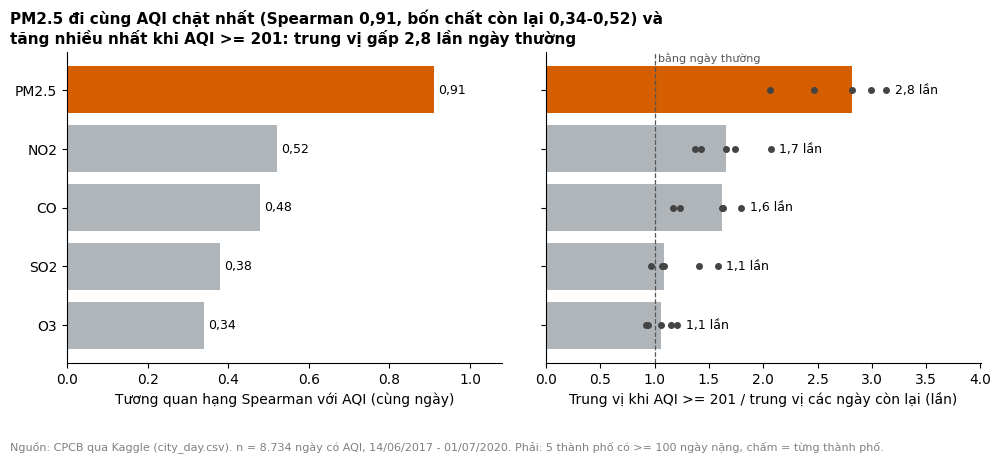

In [4]:
rho = corr["AQI"].drop("AQI").sort_values()                      # tăng dần để cột lớn nằm trên cùng
rt = ratio.loc[big, rho.index]                                   # 5 thành phố, cùng thứ tự chất
rt_med = ratio.loc["Trung vị 5 thành phố", rho.index]
assert rho.idxmax() == "PM2.5" and rt_med.idxmax() == "PM2.5", "PM2.5 không còn đứng đầu, phải sửa tiêu đề"

others = rho.drop("PM2.5")
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 4.6), sharey=True)
colors = [ACCENT if s == "PM2.5" else NEUTRAL for s in rho.index]

# Trái: tương quan hạng với AQI (khoảng chung, 8 thành phố)
b1 = ax1.barh(rho.index, rho.values, color=colors)
ax1.bar_label(b1, labels=[vn(v, 2) for v in rho.values], padding=3, fontsize=9)
ax1.set_xlim(0, 1.08)
ax1.set_xlabel("Tương quan hạng Spearman với AQI (cùng ngày)")
ax1.set_ylabel("")

# Phải: tỉ lệ trung vị ngày nặng / ngày thường, tính trong từng thành phố (chấm xám = từng thành phố)
b2 = ax2.barh(rt_med.index, rt_med.values, color=colors)
for i, s in enumerate(rt_med.index):
    ax2.scatter(rt[s].values, [i] * len(rt), s=16, color="#444444", zorder=3)
    ax2.text(rt[s].max() + 0.08, i, f"{vn(rt_med[s], 1)} lần", va="center", fontsize=9)
ax2.axvline(1, color="#555555", linestyle="--", linewidth=0.9)
ax2.text(1.03, 1.0, "bằng ngày thường", transform=ax2.get_xaxis_transform(), va="top", fontsize=8, color="#555555")
ax2.set_xlim(0, rt.max().max() * 1.28)
ax2.set_xlabel("Trung vị khi AQI >= 201 / trung vị các ngày còn lại (lần)")

finish_chart(fig, ax1,
             f"PM2.5 đi cùng AQI chặt nhất (Spearman {vn(rho['PM2.5'], 2)}, bốn chất còn lại {vn(others.min(), 2)}-{vn(others.max(), 2)}) "
             f"và tăng nhiều nhất khi AQI >= 201: trung vị gấp {vn(rt_med['PM2.5'], 1)} lần ngày thường",
             win, note=f"Phải: {len(big)} thành phố có >= 100 ngày nặng, chấm = từng thành phố.")
fig.subplots_adjust(bottom=0.2, wspace=0.1)       # chừa chỗ cho nhãn trục và chú thích nguồn
# nhãn trục dài đẩy khung vẽ sang phải: dời tiêu đề về mép trái của hình (cùng cách 08a)
fig.canvas.draw()
pos = ax1.get_position()
ax1.set_title(ax1.get_title(loc="left"), loc="left", x=(0.01 - pos.x0) / pos.width, fontsize=11, fontweight="bold")
save_fig(fig, "04_pm25_aqi")
plt.show()

## Phát hiện của phần C

| # | Phát hiện (có con số) | Biểu đồ | Confounder có thể | Hạn chế |
|---|---|---|---|---|
| C1 | Trong khoảng chung 14/06/2017 - 01/07/2020, PM2.5 là chất đi cùng AQI chặt nhất (Spearman 0,91; NO2 0,52, CO 0,48, SO2 0,38, O3 0,34). Vào ngày AQI >= 201, trung vị PM2.5 cao gấp 2,1-3,1 lần ngày thường ở cả 5 thành phố có từ 100 ngày nặng (trung vị 2,8 lần; 137 so với 42 µg/m³ khi gộp). NO2 gấp 1,7 lần, CO 1,6 lần, SO2 và O3 chỉ khoảng 1,1 lần. | 4 | **Cách tính AQI:** AQI lấy chỉ số con lớn nhất nên PM2.5 cao khi AQI cao một phần là do công thức; ngày nặng lại được chọn theo chính AQI. **Mùa:** 73,2% ngày nặng rơi vào tháng 10-2, mọi chất đều cao hơn vào mùa này nên NO2, CO cao hơn có thể do thời tiết chung. **PM10** bị loại khỏi so sánh. | 225/1.850 ngày nặng (12,2%) có PM2.5 < 91 µg/m³ (chỉ số con chưa tới 201): ở đó chất quyết định là chất khác hoặc số liệu có vấn đề (Jaipur 44/121 ngày). Chỉ mô tả "chất nào cao hơn bình thường", **không** nói chất nào "đóng góp" bao nhiêu (nhóm thử dựng lại AQI từ các chất theo bảng CPCB chỉ khớp khoảng 33% số ngày). Chỉ có tương quan. |
| C2 | Phần "chất nào" chỉ áp dụng cho 5 thành phố có ngày nặng: Delhi 564, Lucknow 516, Gurugram 495, Jaipur 121, Amritsar 117 ngày. Chennai chỉ có 34 ngày, Bengaluru 2 và Hyderabad 1 ngày AQI >= 201, quá ít để nói về chất nào. | 4 (nửa phải) | Thành phố nhiều ngày nặng cũng là thành phố có mùa đông lạnh và khô ở phía bắc, nên "chất nào" ở nhóm này có thể không đúng cho phía nam (giả thuyết, dữ liệu không có thời tiết). | Với 3 thành phố phía nam, kết luận về chất chỉ có thể là "hầu như không có ngày nặng" (xem biểu đồ 1), không phải "chất X cao nhất". |


---
## Tổng hợp cuối

### Mục 5: 5 phát hiện chính
Lấy từ ba bảng "phát hiện của phần ..." (08a, 08b, 08c). Mỗi ý gắn đúng một biểu đồ; tất cả so sánh giữa thành phố dùng khoảng chung 14/06/2017 - 01/07/2020, trừ phát hiện 4.

| # | Phát hiện chính | Biểu đồ | Từ notebook |
|---|---|---|---|
| 1 | **Ở đâu:** Delhi (51,0%), Lucknow (46,4%) và Gurugram (46,3%) có khoảng một nửa số ngày AQI >= 201, gấp 4,1-4,6 lần Amritsar (11,4%) và Jaipur (11,1%). Chennai (3,1%), Bengaluru (0,2%) và Hyderabad (0,1%) gần như không có ngày nặng. Chỉ đọc theo ba nhóm, không xếp hạng từng thành phố. | 1 | 08a (A1) |
| 2 | **Khi nào:** AQI trung vị cao nhất vào tháng 11-12 và thấp nhất vào tháng 7-9 ở Delhi, Gurugram, Lucknow, Jaipur và Amritsar (Delhi: 376 vào tháng 12 so với 98 vào tháng 8). Ở Amritsar, 89/117 ngày nặng (76%) rơi vào tháng 10-12. Bengaluru gần như không có mùa (trung vị tháng 63-102). | 2 | 08b (B1) |
| 3 | **Chất nào:** PM2.5 đi cùng AQI chặt nhất (Spearman 0,91; các chất khác 0,34-0,52) và tăng nhiều nhất vào ngày AQI >= 201: trung vị gấp 2,8 lần ngày thường, NO2 1,7 lần, CO 1,6 lần, SO2 và O3 khoảng 1,1 lần. Một phần là do công thức tính AQI. | 4 | 08c (C1) |
| 4 | **Xu hướng:** cùng kỳ tháng 1-6, AQI năm 2020 thấp hơn 2019 ở cả 8 thành phố (giảm 10% ở Amritsar đến 30% ở Lucknow), nhưng 7/8 thành phố đã thấp hơn 2019 trước phong tỏa 25/3 (giảm 7% đến 33%; riêng Amritsar tăng 16%), nên không thể gán toàn bộ cho phong tỏa. | 3 | 08b (B2) |
| 5 | **Mức dao động:** trung vị AQI của ba thành phố đầu là 188-205, so với 81-122 ở năm thành phố còn lại. Lucknow dao động rộng nhất (IQR 211), phần lớn là chênh lệch mùa: trung vị mùa đông 325, mùa mưa 91. | 5 | 08a (A2) |

### Mục 6: hạn chế (cụ thể, mỗi ý gắn với kết luận mà nó đe dọa)

Số liệu trong bảng đã tự kiểm lại bằng `win` và bảng độ nhạy ở `08_eda.ipynb`.

| # | Hạn chế (cụ thể) | Kết luận bị đe dọa | Có thể làm đổi bao nhiêu |
|---|---|---|---|
| 1 | Khoảng chung chỉ gần 3 năm (14/06/2017 - 01/07/2020), mỗi ô thành phố x tháng chỉ có 75-107 ngày từ khoảng 3 mùa. | Mùa cao điểm (biểu đồ 2) và % ngày nặng (biểu đồ 1). | Một năm bất thường làm lệch trung vị tháng. Thử bỏ ngẫu nhiên 10% ngày (200 lần): % ngày nặng đổi khoảng 2 điểm phần trăm (Delhi 49,3-53,1%), nhóm đầu (44,6-53,1%) vẫn tách khỏi nhóm giữa (10,0-12,2%). |
| 2 | Hai thành phố có tỉ lệ gần nhau đổi chỗ khi bỏ 10% dòng: Lucknow và Gurugram giữ đúng thứ hạng chỉ 59% số lần, Amritsar và Jaipur 76%. | Câu "thành phố X nặng hơn Y". | Không xếp hạng trong cùng nhóm; chỉ kết luận giữa các nhóm. |
| 3 | Mỗi thành phố chỉ có một chuỗi; dữ liệu không có vị trí và số trạm đo, không có thời tiết. | Mọi kết luận "ở đâu" và "vì sao" (biểu đồ 1, 2, 5). | Không định lượng được. Vì vậy báo cáo chỉ viết "có liên quan", không viết "gây ra". |
| 4 | PM10 không dùng được (thiếu 100% ở Lucknow, 84,5% ở Chennai, 52,4% ở Gurugram); NH3 thiếu 92,9% ở Gurugram. So sánh chất chỉ gồm 5 chất (PM2.5, NO2, CO, SO2, O3). | "PM2.5 là chất cao nhất khi AQI nặng" (biểu đồ 4). | 225/1.850 ngày nặng (12,2%) có PM2.5 < 91 µg/m³ nên chưa đủ làm AQI >= 201; ở Jaipur là 44/121 ngày (36%). Ở những ngày đó chất quyết định nằm ngoài 5 chất hoặc số liệu có vấn đề. |
| 5 | AQI tính từ chỉ số con lớn nhất của các chất, nên AQI và PM2.5 liên hệ một phần do công thức; nhóm thử dựng lại AQI chỉ khớp khoảng 33% số ngày. | "PM2.5 chiếm bao nhiêu phần AQI" (biểu đồ 4). | Không trả lời được; báo cáo chỉ nói chất nào cao hơn bình thường, không nói đóng góp. |
| 6 | 24 ngày (41 ô) nghi lỗi cảm biến đã đặt NaN nhưng chưa đối chiếu nguồn CPCB; còn điểm chưa xử lý (Gurugram 30/08/2017: PM2.5 643,7, AQI 891, hai ngày cạnh PM2.5 chỉ 6,4 và 33,3). | Đỉnh của PM2.5 và AQI, độ lệch `skew`, `std` (biểu đồ 5). | % ngày nặng gần như không đổi (1 ngày trong 1.070 ngày có AQI của Gurugram, khoảng 0,1 điểm phần trăm), nhưng `skew` và `std` của Gurugram bị kéo lên. |
| 7 | Dữ liệu dừng ở 01/07/2020: không có mùa cao điểm 10-12/2020; năm 2020 có phong tỏa từ 25/3; mỗi đoạn so 2020 với 2019 chỉ 81-98 ngày; Amritsar chỉ có từ 27/02/2017. | "AQI 2020 thấp hơn 2019" (biểu đồ 3). | Phong tỏa không giải thích hết: 7/8 thành phố đã giảm 7-33% trước 25/3, còn Amritsar tăng 16% trước phong tỏa rồi giảm 29% sau. |

### Bộ câu vấn đáp
Câu trả lời ngắn cho 5 câu W8 (xem `08_eda.ipynb`) và các câu riêng của đề tài. Cả nhóm tập trả lời cho **bất kỳ thành phố nào**; số liệu lấy từ `reports/cleaning_log_8cities.md` và các bảng trong notebook 08, 08a, 08b, 08c.

**1. Vì sao xử lý missing theo cách đó?**
Nội suy tuyến tính theo thời gian chỉ cho khoảng thiếu từ 14 ngày trở xuống và nằm giữa hai giá trị thật, vì khoảng ngắn thì đường thẳng hợp lý. Khoảng dài giữ NaN vì nội suy qua khối dài là bịa số (hàm cũ điền nhầm 1.316 ô ở khoảng dài, đã sửa). AQI không điền vì là biến kết quả; điền là tạo kết quả giả.

**2. Cơ chế thiếu của cột này là gì, bằng chứng nào?**
Thiếu theo khối thời gian dài (cảm biến chưa lắp hoặc ngừng): ở 9 cặp (thành phố, cột) thiếu từ 20% trở lên, 100% ngày thiếu nằm trong khoảng dài hơn 14 ngày. Nên không phải thiếu ngẫu nhiên hoàn toàn (MCAR) mà gần với MAR theo thời gian: AQI trung bình ở ngày thiếu và ngày có lệch từ 0% đến +82% tùy cột. Không loại trừ được MNAR (thiếu vì giá trị quá cao hoặc thấp) vì không có nguồn ngoài để đối chiếu.

**3. Nếu xoá ngẫu nhiên 10% dòng, kết luận có đổi không?**
Không đổi kết luận theo nhóm. % ngày nặng chỉ đổi khoảng 2 điểm phần trăm (Delhi 49,3-53,1%) và nhóm đầu vẫn tách khỏi nhóm giữa. Thứ hạng cặp Lucknow-Gurugram giữ chỉ 59% số lần, nên báo cáo chia ba nhóm thay vì xếp hạng từng thành phố.

**4. Biểu đồ này có thể đánh lừa người đọc vội ở chỗ nào? (biểu đồ 4)**
(1) Cột 0,91 trông như một phát hiện, nhưng một phần do công thức tính AQI. (2) Ngày nặng được chọn theo AQI, nên PM2.5 cao hơn ở những ngày đó gần như là điều tất yếu. (3) "2,8 lần" là trung vị của 5 thành phố, từng thành phố từ 2,1 đến 3,1 (các chấm). (4) SO2 và O3 gần bằng ngày thường không có nghĩa là không quan trọng: 12,2% ngày nặng có PM2.5 chưa tới mức nặng, chất quyết định có thể là PM10, vốn không nằm trong biểu đồ. (5) Biểu đồ không nói chất nào gây ra ô nhiễm.

**5. Confounder hợp lý cho quan hệ vừa mô tả là gì?**
Cho biểu đồ 4: **mùa và thời tiết**. 73,2% ngày nặng rơi vào tháng 10-2, mọi chất cùng cao hơn vào mùa này, nên NO2 và CO cao hơn ngày thường có thể là do thời tiết chung (gió yếu, không khí sát mặt đất ít xáo trộn; giả thuyết, dữ liệu không có thời tiết). Thêm nữa: vị trí trạm đo (mỗi thành phố một chuỗi) và PM10 bị loại khỏi so sánh. Cho biểu đồ 1: số và vị trí trạm, quy mô đô thị, địa lý. Cho biểu đồ 3: mùa, xu hướng dài hạn, phong tỏa.

**Câu riêng của đề tài**
- *Vì sao dùng khoảng chung?* Chuỗi mỗi thành phố bắt đầu một thời điểm (Gurugram 27/11/2015, Amritsar 27/02/2017, Jaipur 14/06/2017). Nếu so cả chuỗi, thành phố có chuỗi dài có thêm các mùa đông mà thành phố khác không có, nên chênh lệch phản ánh độ dài chuỗi. Khoảng chung 14/06/2017 - 01/07/2020 cho mọi thành phố cùng 3 mùa đông.
- *Vì sao ngưỡng 201?* Là đầu mức Poor trong thang CPCB (201-300; trên 300 là Very Poor), mức cần cảnh báo sức khỏe. Hạn chế: đường cắt cứng, trung vị Lucknow và Gurugram (188) nằm sát ngưỡng nên % ngày nặng nhạy với việc chọn ngưỡng.
- *Vì sao tháng 1-6 khi so các năm?* Dữ liệu năm 2020 dừng ở 01/07, nên chỉ tháng 1-6 có đủ ở cả 6 năm; so cùng kỳ để không lẫn chênh lệch mùa.
- *Vì sao PM10 và NH3 không dùng làm biến?* Theo quy ước nhóm, cột thiếu từ 60% trở lên thì không dùng: PM10 thiếu 100% ở Lucknow, 84,5% ở Chennai; NH3 thiếu 92,9% ở Gurugram. Vì vậy `USABLE` chỉ gồm 5 chất đủ dữ liệu ở cả 8 thành phố.

**Trước khi push:** Restart & Run All không lỗi; đã tick checklist biểu đồ; đã `git pull`.
